# BRFSS mở rộng — 20 biến, cùng phép chia với notebook 02

Nâng cấp notebook 02 (chỉ 5 biến, ROC-AUC test 0,76). Dùng **cùng 3 file BRFSS 2021–2023 đã tải**, cùng phép chia (2021–22 train/validation, 2023 test theo thời gian), nhưng khai thác thêm 15 biến có mặt ở cả ba năm: sức khỏe tự đánh giá, khó khăn đi lại, bệnh kèm (đột quỵ, mạch vành, thận, COPD, trầm cảm), rượu, bảo hiểm, chi phí khám, học vấn, thu nhập. Bộ biến tương tự bộ *CDC Diabetes Health Indicators* (UCI id 891).

Lưu ý: nhiều biến là **bệnh kèm có thể xuất hiện sau khi mắc đái tháo đường** (nhân quả ngược), nên mô hình phân loại trạng thái hiện tại tốt hơn nhưng không phải dự báo mắc mới. BRFSS là khảo sát Hoa Kỳ tự khai, không dùng survey weight. Chỉ dùng cho học thuật.

## 1. Thiết lập
Chọn dữ liệu, cấu hình và đường dẫn. Mỗi lần chạy tạo một thư mục mới trong `artifacts/notebook_runs/`.

In [1]:
EXPERIMENT = 'brfss20'
MODEL_TYPE = 'MLP'
PURPOSE = 'BRFSS 2021–2023, 20 biến có ở cả ba năm; nhãn tự khai từng được báo mắc ĐTĐ; không dùng survey weight.'
import os, json, hashlib, random, sys, platform
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, brier_score_loss)
import torch
from torch import nn
import joblib
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'docker-compose.yml').exists()), None)
if ROOT is None: raise RuntimeError('Chạy notebook trong thư mục dự án.')
SMOKE = os.getenv('NOTEBOOK_SMOKE') == '1'  # Chỉ dùng cho kiểm thử kỹ thuật, không báo cáo kết quả.
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(1)
run_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN_DIR = (Path('/tmp/duongan_notebook_smoke') if SMOKE else ROOT/'artifacts/notebook_runs') / EXPERIMENT / run_stamp
RUN_DIR.mkdir(parents=True, exist_ok=False)
print('Project:', ROOT, '| kết quả:', RUN_DIR, '| kiểm thử nhanh:', SMOKE)

Project: /Users/handq2212/DaiHoc/Nam4/LTHTTM/project | kết quả: /Users/handq2212/DaiHoc/Nam4/LTHTTM/project/artifacts/notebook_runs/brfss20/20261112T073448_850428Z | kiểm thử nhanh: False


## 2. Đọc và biểu diễn dữ liệu
Đọc dữ liệu gốc và kiểm tra số dòng, cột. Các biểu đồ phân tích chi tiết ở mục 4 chỉ dùng tập train.

In [2]:
import pyreadstat
features = ['_BMI5', '_AGEG5YR', 'SEXVAR', '_SMOKER3', '_TOTINDA', 'GENHLTH', '_PHYS14D', '_MENT14D', 'DIFFWALK', 'CVDSTRK3', '_MICHD', 'CHCKDNY2', 'CHCCOPD3', 'ADDEPEV3', 'HEAVY_DRINK', 'HLTHPLAN', 'MEDCOST1', 'CHECKUP1', '_EDUCAG', '_INCOMG1']
numeric, categorical = ['_BMI5'], [c for c in features if c != '_BMI5']
FEATURE_DESCRIPTIONS = {k: v for k, v in {'_BMI5': 'BMI (kg/m²)', '_AGEG5YR': 'Nhóm tuổi 5 năm (1=18–24 … 13=80+)', 'SEXVAR': 'Giới (1 nam, 2 nữ)', '_SMOKER3': 'Hút thuốc (1–2 hiện tại, 3 đã bỏ, 4 chưa từng)', '_TOTINDA': 'Vận động ngoài công việc 30 ngày qua (1 có, 2 không)', 'GENHLTH': 'Tự đánh giá sức khỏe chung (1 rất tốt … 5 kém)', '_PHYS14D': 'Số ngày sức khỏe thể chất kém (1: 0, 2: 1–13, 3: 14+)', '_MENT14D': 'Số ngày sức khỏe tinh thần kém (1: 0, 2: 1–13, 3: 14+)', 'DIFFWALK': 'Khó khăn đi bộ/leo cầu thang (1 có, 2 không)', 'CVDSTRK3': 'Từng được báo đột quỵ (1 có, 2 không)', '_MICHD': 'Từng bệnh mạch vành/nhồi máu (1 có, 2 không)', 'CHCKDNY2': 'Từng được báo bệnh thận (1 có, 2 không)', 'CHCCOPD3': 'Từng được báo COPD (1 có, 2 không)', 'ADDEPEV3': 'Từng được báo trầm cảm (1 có, 2 không)', 'HEAVY_DRINK': 'Uống rượu nhiều (1 không, 2 có); 2021 _RFDRHV7, 2022–23 _RFDRHV8', 'HLTHPLAN': 'Có bảo hiểm y tế (1 có, 2 không); 2021–22 _HLTHPLN, 2023 _HLTHPL1', 'MEDCOST1': 'Không đi khám được vì chi phí (1 có, 2 không)', 'CHECKUP1': 'Lần khám tổng quát gần nhất (1 <1 năm … 4 ≥5 năm, 8 chưa bao giờ)', '_EDUCAG': 'Học vấn (1–4)', '_INCOMG1': 'Nhóm thu nhập (1–7)', '_RFHYPE6': 'Từng được báo tăng huyết áp (1 không, 2 có) — chỉ có ở năm lẻ', '_RFCHOL3': 'Từng được báo cholesterol cao (1 không, 2 có) — chỉ có ở năm lẻ'}.items() if k in features}
EXTRA_REPORT = {'variant': 'A_all_years_20_features', 'comparison_baseline': 'notebook 02 (5 features), same split'}
# Một số biến đổi tên giữa các năm: gộp về cùng một tên (đã đối chiếu codebook CDC từng năm).
RENAMES = {2021: {'_RFDRHV7': 'HEAVY_DRINK', '_HLTHPLN': 'HLTHPLAN'},
           2022: {'_RFDRHV8': 'HEAVY_DRINK', '_HLTHPLN': 'HLTHPLAN'},
           2023: {'_RFDRHV8': 'HEAVY_DRINK', '_HLTHPL1': 'HLTHPLAN'}}
YEARS = [2021, 2022, 2023]  # năm cuối là tập test theo thời gian
source_paths = [ROOT/f'data/raw/LLCP{year}.XPT' for year in YEARS]
def read_survey(path, year):
    inverse = {new: old for old, new in RENAMES[year].items()}
    usecols = [inverse.get(c, c) for c in features] + ['DIABETE4']
    kwargs = {'row_limit': 12000} if SMOKE else {}
    frame, _ = pyreadstat.read_xport(str(path), usecols=usecols, encoding='latin1', **kwargs)
    missing = set(usecols) - set(frame.columns)
    if missing: raise ValueError(f'{year} thiếu cột {sorted(missing)}; kiểm tra codebook trước khi đổi danh sách biến')
    return frame.rename(columns=RENAMES[year])
raw = [read_survey(path, year) for path, year in zip(source_paths, YEARS)]
print('Số dòng gốc đọc từng năm:', dict(zip(YEARS, [len(x) for x in raw])))

Số dòng gốc đọc từng năm: {2021: 438693, 2022: 445132, 2023: 433323}


## 3. Làm sạch, định nghĩa nhãn và chia tập
Loại nhãn không hợp lệ, kiểm soát dữ liệu thiếu và tách test. Các phép học tham số xử lý dữ liệu chỉ được fit sau khi chia tập.

In [3]:
codes = {k: v for k, v in {'_AGEG5YR': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13], 'SEXVAR': [1, 2], '_SMOKER3': [1, 2, 3, 4], '_TOTINDA': [1, 2], 'GENHLTH': [1, 2, 3, 4, 5], '_PHYS14D': [1, 2, 3], '_MENT14D': [1, 2, 3], 'DIFFWALK': [1, 2], 'CVDSTRK3': [1, 2], '_MICHD': [1, 2], 'CHCKDNY2': [1, 2], 'CHCCOPD3': [1, 2], 'ADDEPEV3': [1, 2], 'HEAVY_DRINK': [1, 2], 'HLTHPLAN': [1, 2], 'MEDCOST1': [1, 2], 'CHECKUP1': [1, 2, 3, 4, 8], '_EDUCAG': [1, 2, 3, 4], '_INCOMG1': [1, 2, 3, 4, 5, 6, 7], '_RFHYPE6': [1, 2], '_RFCHOL3': [1, 2]}.items() if k in features}
def clean_survey(frame):
    # Nhãn DIABETE4: 1 = từng được báo mắc ĐTĐ, 3 = không. Loại 2 (thai kỳ), 4 (tiền ĐTĐ), 7/9/trống.
    df = frame[frame.DIABETE4.isin([1, 3])].copy()
    df['class'] = df.DIABETE4.map({1: 1, 3: 0})
    df['_BMI5'] = (pd.to_numeric(df['_BMI5'], errors='coerce') / 100).where(lambda x: x.between(10, 100))
    for col, valid in codes.items():
        values = pd.to_numeric(df[col], errors='coerce')
        # Mã 7/9 (không biết/từ chối) và trống trở thành thiếu, được impute bằng giá trị hay gặp nhất của train.
        df[col] = values.where(values.isin(valid)).astype('Int64').astype('string')
    return df[features + ['class']]
frames = [clean_survey(frame) for frame in raw]
trainval, test = pd.concat(frames[:-1], ignore_index=True), frames[-1]
train, val = train_test_split(trainval, test_size=0.2, stratify=trainval['class'], random_state=SEED)
print('Sau lọc nhãn theo năm:', dict(zip(YEARS, [len(f) for f in frames])))
print('Tỷ lệ nhãn 1 theo năm:', dict(zip(YEARS, [round(float(f["class"].mean()), 4) for f in frames])))

Sau lọc nhãn theo năm: {2021: 423958, 2022: 429880, 2023: 418492}
Tỷ lệ nhãn 1 theo năm: {2021: 0.1359, 2022: 0.1423, 2023: 0.1429}


## 4. Biểu diễn và phân tích dữ liệu train
Kiểm tra phân bố nhãn, thiếu dữ liệu, thống kê, histogram theo nhãn và tương quan các biến số. Mẫu hiển thị có thể được giới hạn để vẽ nhanh; huấn luyện dùng toàn bộ tập train.

train: 683070 mẫu; nhãn: {0: 588051, 1: 95019}
validation: 170768 mẫu; nhãn: {0: 147013, 1: 23755}
test: 418492 mẫu; nhãn: {0: 358706, 1: 59786}

Thiếu dữ liệu trên train (%):


_INCOMG1       21.47
_BMI5          10.73
HEAVY_DRINK     9.56
_SMOKER3        6.81
DIFFWALK        4.94
HLTHPLAN        3.97
_PHYS14D        2.25
_AGEG5YR        2.07
_MENT14D        1.88
CHECKUP1        1.30
_MICHD          1.00
ADDEPEV3        0.52
_EDUCAG         0.51
CHCCOPD3        0.41
CHCKDNY2        0.34
MEDCOST1        0.31
CVDSTRK3        0.27
GENHLTH         0.25
_TOTINDA        0.21
SEXVAR          0.00

Thống kê biến số trên train:
           _BMI5
count  609786.00
mean       28.46
std         6.51
min        12.00
25%        24.05
50%        27.40
75%        31.62
max        99.64


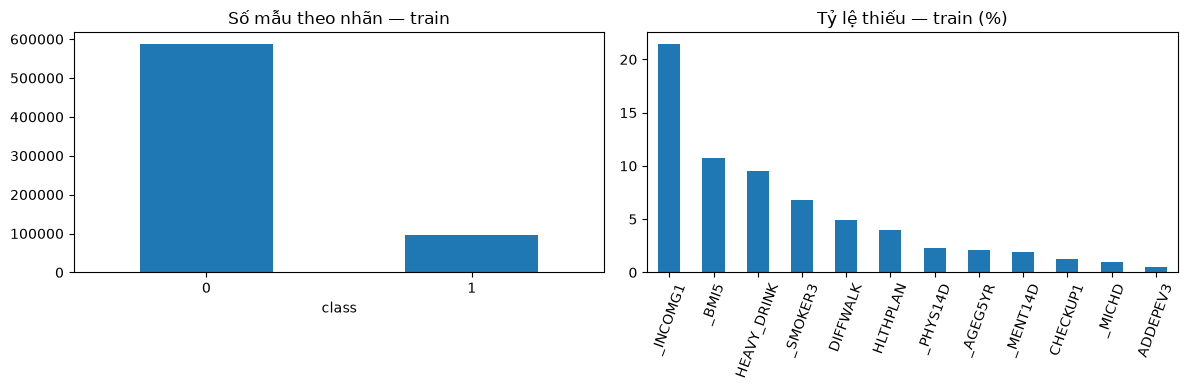

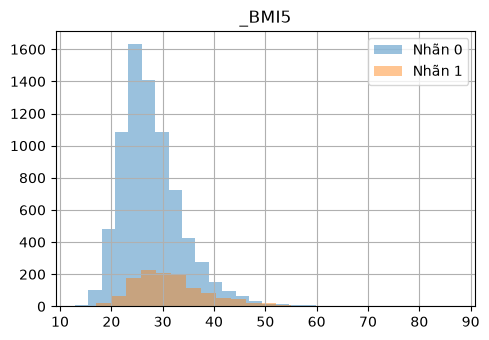

In [4]:
# Phân tích trên tập train để không dùng test quyết định đặc trưng.
for name, frame in [('train',train),('validation',val),('test',test)]:
    counts = frame['class'].value_counts().sort_index().to_dict()
    print(f'{name}: {len(frame)} mẫu; nhãn: {counts}')
    if frame['class'].nunique() != 2: raise ValueError(f'{name} cần đủ hai lớp')
print('\nThiếu dữ liệu trên train (%):')
print((train[features].isna().mean().sort_values(ascending=False)*100).round(2).to_string())
print('\nThống kê biến số trên train:')
print(train[numeric].describe().round(2).to_string())
fig,axes=plt.subplots(1,2,figsize=(12,4))
train['class'].value_counts().sort_index().plot.bar(ax=axes[0],title='Số mẫu theo nhãn — train',rot=0)
(train[features].isna().mean()*100).sort_values(ascending=False).head(12).plot.bar(ax=axes[1],title='Tỷ lệ thiếu — train (%)',rot=70)
plt.tight_layout(); plt.show()
# Số mẫu lớn chỉ lấy tối đa 10.000 điểm train cho biểu đồ, không thay đổi dữ liệu huấn luyện.
visual=train.sample(n=min(10000,len(train)),random_state=SEED)
plot_cols=numeric[:min(4,len(numeric))]
fig,axes=plt.subplots(1,len(plot_cols),figsize=(5*len(plot_cols),3.5),squeeze=False)
for ax,col in zip(axes[0],plot_cols):
    for label in (0,1):
        visual.loc[visual['class']==label,col].dropna().hist(ax=ax,bins=25,alpha=.45,label=f'Nhãn {label}')
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()
if len(numeric)>1:
    corr=visual[numeric].corr(numeric_only=True)
    fig,ax=plt.subplots(figsize=(max(6,len(corr)*.65),max(5,len(corr)*.65)))
    im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
    ax.set_xticks(range(len(corr)),corr.columns,rotation=75,ha='right'); ax.set_yticks(range(len(corr)),corr.index)
    ax.set_title('Tương quan các biến số — train'); fig.colorbar(im,ax=ax); plt.tight_layout(); plt.show()

## 5. Tiền xử lý
Điền khuyết và chuẩn hóa trên train; biến phân loại one-hot. Áp dụng các phép biến đổi đã học lên validation/test.

In [5]:
def frame_x(frame):
    x=frame[features].copy()
    for col in categorical: x[col]=x[col].astype(object).where(x[col].notna(),np.nan)
    return x
parts=[]
if numeric: parts.append(('num',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),numeric))
if categorical: parts.append(('cat',make_pipeline(SimpleImputer(strategy='most_frequent'),OneHotEncoder(handle_unknown='ignore')),categorical))
preprocessor=ColumnTransformer(parts,sparse_threshold=0)
Xtr=preprocessor.fit_transform(frame_x(train)).astype('float32')
Xva=preprocessor.transform(frame_x(val)).astype('float32')
Xte=preprocessor.transform(frame_x(test)).astype('float32')
ytr,yva,yte=[f['class'].to_numpy(dtype='float32') for f in (train,val,test)]
print('Kích thước sau tiền xử lý:',Xtr.shape,Xva.shape,Xte.shape)

Kích thước sau tiền xử lý: (683070, 67) (170768, 67) (418492, 67)


## 6. Định nghĩa mô hình và baseline
Mạng nơ-ron so sánh với Dummy, Logistic Regression và HistGradientBoosting. CNN 1D trên dữ liệu bảng là giả định thực nghiệm về thứ tự cột.

In [6]:
# So sánh với baseline đơn giản và mô hình phi tuyến trên cùng dữ liệu.
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, roc_curve, precision_recall_curve
class Net(nn.Module):
    def __init__(self,n):
        super().__init__()
        if MODEL_TYPE=='MLP':
            self.net=nn.Sequential(nn.Linear(n,64),nn.ReLU(),nn.Dropout(.2),nn.Linear(64,32),nn.ReLU(),nn.Linear(32,1))
        else:
            self.net=nn.Sequential(nn.Unflatten(1,(1,n)),nn.Conv1d(1,16,3,padding=1),nn.ReLU(),nn.Conv1d(16,32,3,padding=1),nn.ReLU(),nn.MaxPool1d(2),nn.Flatten(),nn.Linear(32*(n//2),32),nn.ReLU(),nn.Dropout(.2),nn.Linear(32,1))
    def forward(self,x): return self.net(x).squeeze(-1)
print('Kiến trúc ứng viên:'); print(Net(Xtr.shape[1]))
print('So sánh thêm: Dummy prior, Logistic Regression, HistGradientBoosting.')

Kiến trúc ứng viên:
Net(
  (net): Sequential(
    (0): Linear(in_features=67, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=1, bias=True)
  )
)
So sánh thêm: Dummy prior, Logistic Regression, HistGradientBoosting.


## 7. Huấn luyện và kiểm tra hội tụ
Tối đa 200 epoch, tối thiểu 40 epoch và dừng sớm nếu validation loss không cải thiện trong 25 epoch. Chạy ba seed khởi tạo; đồ thị hiển thị train/validation loss, epoch tốt nhất và số bước cập nhật. Seed chỉ đo độ nhạy khởi tạo, không thay thế kiểm định trên nhiều tập chia độc lập.

Training dummy


Training logistic_regression


Training hist_gradient_boosting


seed=42: epochs=40, best=10, updates=6680, val AUC=0.8261, early_stop=True


seed=43: epochs=42, best=17, updates=7014, val AUC=0.8260, early_stop=True


seed=44: epochs=44, best=19, updates=7348, val AUC=0.8259, early_stop=True


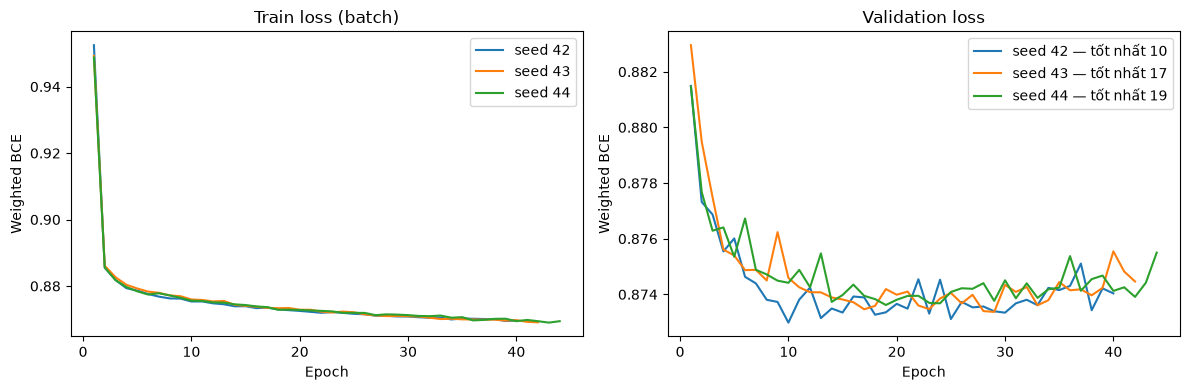

Dao động validation AUC giữa các seed: [0.8261, 0.826, 0.8259]


In [7]:
# Cùng tập train/validation cho tất cả ứng viên. Ba seed chỉ thay đổi khởi tạo,
# không thay thế việc đánh giá trên nhiều phép chia dữ liệu độc lập.
from copy import deepcopy
candidates = {
    'dummy':DummyClassifier(strategy='prior'),
    'logistic_regression':LogisticRegression(max_iter=1000,class_weight='balanced',random_state=SEED),
    'hist_gradient_boosting':HistGradientBoostingClassifier(max_iter=100 if not SMOKE else 5,max_leaf_nodes=15,class_weight='balanced',random_state=SEED),
}
for name, estimator in candidates.items():
    print('Training',name,flush=True); estimator.fit(Xtr,ytr)

seeds=[42] if SMOKE else [42,43,44]
max_epochs=2 if SMOKE else 200
min_epochs=1 if SMOKE else 40
patience_limit=2 if SMOKE else 25
# Batch lớn giúp bộ BRFSS khả thi; số lần cập nhật thực tế được lưu trong report.
batch_size=4096 if EXPERIMENT.startswith('brfss') else 64
xt,yt=torch.tensor(Xtr),torch.tensor(ytr)
xv,yv=torch.tensor(Xva),torch.tensor(yva)
pos_weight=torch.tensor([(len(ytr)-sum(ytr))/sum(ytr)],dtype=torch.float32)
loss_fn=nn.BCEWithLogitsLoss(pos_weight=pos_weight)
runs=[]
for run_seed in seeds:
    torch.manual_seed(run_seed); random.seed(run_seed); np.random.seed(run_seed)
    model=Net(Xtr.shape[1]); optimizer=torch.optim.Adam(model.parameters(),lr=0.001)
    generator=torch.Generator().manual_seed(run_seed)
    loader=torch.utils.data.DataLoader(torch.utils.data.TensorDataset(xt,yt),batch_size=batch_size,shuffle=True,generator=generator)
    best_loss=float('inf'); best_state=None; best_epoch=0; patience=0; history=[]; updates=0
    for epoch in range(1,max_epochs+1):
        model.train(); total_loss=0.0
        for x,y in loader:
            optimizer.zero_grad(); loss=loss_fn(model(x),y); loss.backward(); optimizer.step()
            total_loss+=float(loss.detach())*len(y); updates+=1
        model.eval()
        with torch.no_grad(): val_loss=float(loss_fn(model(xv),yv))
        history.append({'epoch':epoch,'train_loss':total_loss/len(ytr),'val_loss':val_loss})
        if val_loss < best_loss - 1e-4:
            best_loss=val_loss; best_epoch=epoch; best_state=deepcopy(model.state_dict()); patience=0
        else: patience+=1
        if epoch>=min_epochs and patience>=patience_limit: break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad(): valid_scores=torch.sigmoid(model(xv)).numpy()
    run={'seed':run_seed,'model':model,'best_epoch':best_epoch,'epochs_run':len(history),
         'updates':updates,'stopped_early':len(history)<max_epochs,'history':history,
         'val_scores':valid_scores,'val_auc':float(roc_auc_score(yva,valid_scores))}
    runs.append(run)
    print(f"seed={run_seed}: epochs={len(history)}, best={best_epoch}, updates={updates}, val AUC={run['val_auc']:.4f}, early_stop={run['stopped_early']}",flush=True)

fig,axes=plt.subplots(1,2,figsize=(12,4))
for run in runs:
    curve=pd.DataFrame(run['history'])
    axes[0].plot(curve.epoch,curve.train_loss,label=f"seed {run['seed']}")
    axes[1].plot(curve.epoch,curve.val_loss,label=f"seed {run['seed']} — tốt nhất {run['best_epoch']}")
for ax,title in zip(axes,['Train loss (batch)','Validation loss']): ax.set_title(title); ax.set_xlabel('Epoch'); ax.set_ylabel('Weighted BCE'); ax.legend()
plt.tight_layout(); plt.show()
print('Dao động validation AUC giữa các seed:',[round(r['val_auc'],4) for r in runs])

## 8. So sánh và lựa chọn trên validation
Bảng so sánh ROC-AUC, PR-AUC, precision, recall, F1; chọn ứng viên theo ROC-AUC validation, sau đó chọn ngưỡng theo F1 validation. Test không tham gia lựa chọn.

Bảng validation (ngưỡng tham khảo 0.5):
                        roc_auc  pr_auc  precision  recall      f1
neural_seed_42           0.8261  0.4253     0.2933  0.8131  0.4311
neural_seed_43           0.8260  0.4249     0.2966  0.8059  0.4336
neural_seed_44           0.8259  0.4250     0.2989  0.7996  0.4351
hist_gradient_boosting   0.8251  0.4242     0.2983  0.7996  0.4345
logistic_regression      0.8208  0.4094     0.3045  0.7775  0.4376
dummy                    0.5000  0.1391     0.0000  0.0000  0.0000


Chọn theo validation ROC-AUC: neural_seed_42 | ngưỡng F1 trên validation: 0.65
 threshold  precision  recall     f1
      0.05     0.1599  0.9956 0.2755
      0.10     0.1789  0.9868 0.3029
      0.15     0.1945  0.9760 0.3244
      0.20     0.2084  0.9640 0.3427
      0.25     0.2208  0.9476 0.3581
      0.30     0.2331  0.9308 0.3729
      0.35     0.2466  0.9111 0.3881
      0.40     0.2602  0.8847 0.4022
      0.45     0.2758  0.8524 0.4168
      0.50     0.2933  0.8131 0.4311
      0.55     0.3137  0.7640 0.4448
      0.60     0.3384  0.7023 0.4568
      0.65     0.3672  0.6265 0.4630
      0.70     0.4021  0.5346 0.4590
      0.75     0.4463  0.4231 0.4344
      0.80     0.4987  0.2962 0.3717
      0.85     0.5678  0.1685 0.2598
      0.90     0.6513  0.0617 0.1127
      0.95     0.7184  0.0062 0.0124


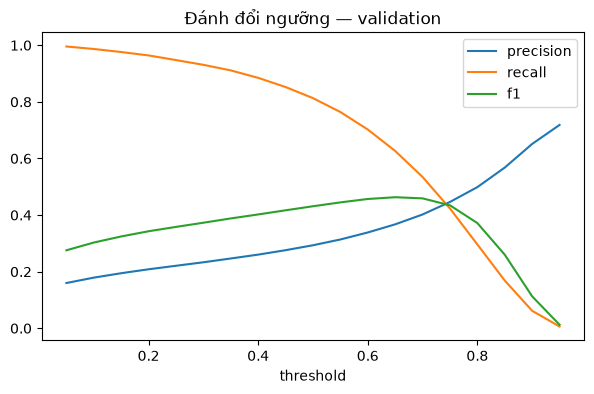

In [8]:
# So sánh validation theo nhiều chỉ số. AUC quyết định mô hình; ngưỡng F1 được chọn riêng trên validation.
val_scores={name:est.predict_proba(Xva)[:,1] for name,est in candidates.items()}
for run in runs: val_scores[f"neural_seed_{run['seed']}"]=run['val_scores']
def threshold_scores(y, scores, threshold):
    pred=(scores>=threshold).astype(int)
    return {'roc_auc':float(roc_auc_score(y,scores)),'pr_auc':float(average_precision_score(y,scores)),
            'precision':float(precision_score(y,pred,zero_division=0)),'recall':float(recall_score(y,pred,zero_division=0)),
            'f1':float(f1_score(y,pred,zero_division=0))}
validation_table=pd.DataFrame({name:threshold_scores(yva,s,.5) for name,s in val_scores.items()}).T.sort_values('roc_auc',ascending=False)
print('Bảng validation (ngưỡng tham khảo 0.5):'); print(validation_table.round(4).to_string())
# Nếu bằng AUC, ưu tiên baseline đơn giản theo thứ tự khai báo.
priority=list(val_scores)
selected=max(priority,key=lambda name:roc_auc_score(yva,val_scores[name]))
threshold_grid=np.round(np.linspace(.05,.95,19),2)
threshold_table=pd.DataFrame([{'threshold':float(t),**threshold_scores(yva,val_scores[selected],t)} for t in threshold_grid])
selected_threshold=float(threshold_table.loc[threshold_table.f1.idxmax(),'threshold'])
print('Chọn theo validation ROC-AUC:',selected,'| ngưỡng F1 trên validation:',selected_threshold)
print(threshold_table[['threshold','precision','recall','f1']].round(4).to_string(index=False))
threshold_table.plot(x='threshold',y=['precision','recall','f1'],title='Đánh đổi ngưỡng — validation',figsize=(7,4));plt.show()
# Ngưỡng F1 là lựa chọn thực nghiệm, không phải ngưỡng lâm sàng.

## 9. Đánh giá test của mô hình đã chọn
Bảng chỉ số, báo cáo phân loại, ROC, Precision–Recall, ma trận nhầm lẫn và khoảng bootstrap phân tầng. Đây là đánh giá học thuật không trọng số; tập test đã từng được sử dụng trong các lần chạy trước và không còn hoàn toàn độc lập.

Kết quả test CHỈ của ứng viên được chọn:
{
  "roc_auc": 0.8216844594963476,
  "pr_auc": 0.42508340383549137,
  "precision": 0.36500188484104507,
  "recall": 0.631619442678888,
  "f1": 0.46264770924327536,
  "accuracy": 0.7903926478881317,
  "brier": 0.18790188431739807,
  "confusion_matrix": [
    [
      293011,
      65695
    ],
    [
      22024,
      37762
    ]
  ]
}
Báo cáo phân loại:
              precision    recall  f1-score   support

         0.0       0.93      0.82      0.87    358706
         1.0       0.37      0.63      0.46     59786

    accuracy                           0.79    418492
   macro avg       0.65      0.72      0.67    418492
weighted avg       0.85      0.79      0.81    418492



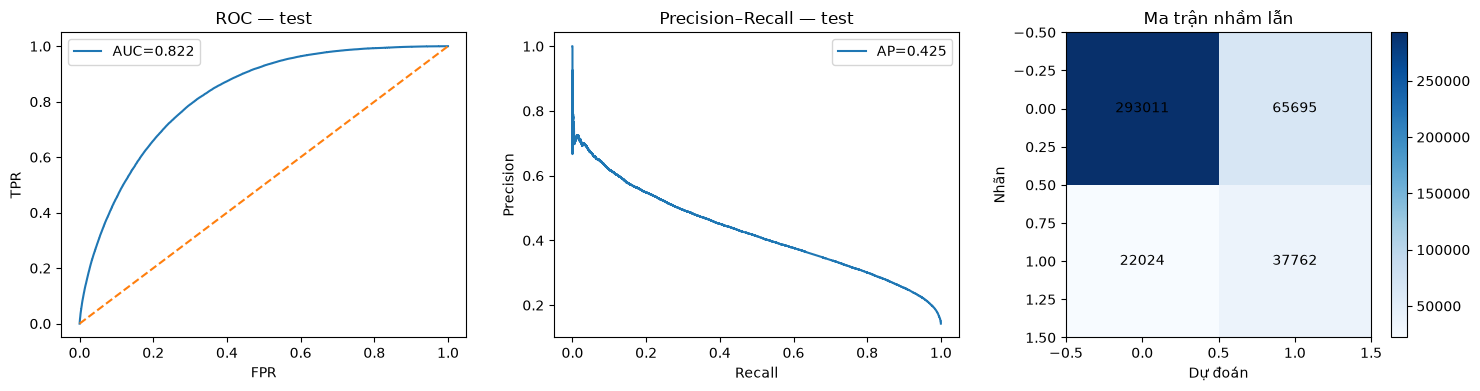

Khoảng bootstrap phân tầng 95% cho ROC-AUC (không tính thiết kế khảo sát): [0.8198313168585762, 0.8231744093780253]
Lưu ý: dữ liệu test đã từng được xem trong các lần chạy trước; đây không còn là kiểm định cuối hoàn toàn độc lập.


In [9]:
if selected.startswith('neural_seed_'):
    best_run=next(r for r in runs if selected==f"neural_seed_{r['seed']}")
    best_run['model'].eval()
    with torch.no_grad(): test_scores=torch.sigmoid(best_run['model'](torch.tensor(Xte))).numpy()
else: test_scores=candidates[selected].predict_proba(Xte)[:,1]
pred=(test_scores>=selected_threshold).astype(int)
test_metrics={**threshold_scores(yte,test_scores,selected_threshold),
    'accuracy':float(accuracy_score(yte,pred)),'brier':float(brier_score_loss(yte,test_scores)),
    'confusion_matrix':confusion_matrix(yte,pred,labels=[0,1]).tolist()}
print('Kết quả test CHỈ của ứng viên được chọn:'); print(json.dumps(test_metrics,indent=2))
print('Báo cáo phân loại:');print(classification_report(yte,pred,zero_division=0))
fpr,tpr,_=roc_curve(yte,test_scores); prec,rec,_=precision_recall_curve(yte,test_scores)
fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].plot(fpr,tpr,label=f"AUC={test_metrics['roc_auc']:.3f}");axes[0].plot([0,1],[0,1],'--');axes[0].set(xlabel='FPR',ylabel='TPR',title='ROC — test');axes[0].legend()
axes[1].plot(rec,prec,label=f"AP={test_metrics['pr_auc']:.3f}");axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–Recall — test');axes[1].legend()
cm=np.array(test_metrics['confusion_matrix']); im=axes[2].imshow(cm,cmap='Blues'); axes[2].set(xlabel='Dự đoán',ylabel='Nhãn',title='Ma trận nhầm lẫn')
for (i,j),value in np.ndenumerate(cm): axes[2].text(j,i,str(value),ha='center',va='center')
fig.colorbar(im,ax=axes[2]);plt.tight_layout();plt.show()
# Bootstrap phân tầng, cố định số lượng mỗi lớp: khoảng mô tả có điều kiện theo mẫu test.
rng=np.random.default_rng(SEED); neg=np.flatnonzero(yte==0); pos=np.flatnonzero(yte==1)
bootstrap=[]
for _ in range(10 if SMOKE else 100):
    ix=np.concatenate([rng.choice(neg,len(neg),replace=True),rng.choice(pos,len(pos),replace=True)])
    bootstrap.append(roc_auc_score(yte[ix],test_scores[ix]))
auc_ci=np.quantile(bootstrap,[.025,.975]).tolist()
print('Khoảng bootstrap phân tầng 95% cho ROC-AUC (không tính thiết kế khảo sát):',auc_ci)
print('Lưu ý: dữ liệu test đã từng được xem trong các lần chạy trước; đây không còn là kiểm định cuối hoàn toàn độc lập.')

## 9b. Độ quan trọng đặc trưng
Mô hình đã chọn dựa vào biến nào nhiều nhất? Đo trên validation, không dùng test.

ROC-AUC gốc trên mẫu validation: 0.8222
_AGEG5YR       0.0741
GENHLTH        0.0433
_BMI5          0.0374
CHECKUP1       0.0223
CHCKDNY2       0.0048
_MICHD         0.0040
SEXVAR         0.0029
HEAVY_DRINK    0.0025
_INCOMG1       0.0025
_EDUCAG        0.0021
_SMOKER3       0.0016
DIFFWALK       0.0016
_TOTINDA       0.0015
CHCCOPD3       0.0013
CVDSTRK3       0.0012
_MENT14D       0.0006
_PHYS14D       0.0004
MEDCOST1       0.0002
ADDEPEV3       0.0002
HLTHPLAN       0.0001


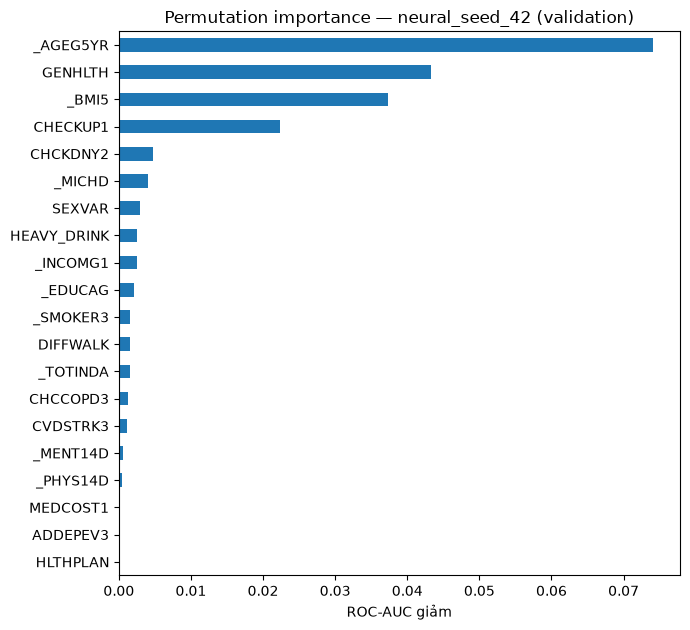

In [10]:
# Độ quan trọng đặc trưng (permutation importance) trên VALIDATION cho mô hình đã chọn.
# Xáo trộn từng cột gốc rồi đo ROC-AUC giảm bao nhiêu: giảm càng nhiều, mô hình càng dựa vào biến đó.
# Đây là mức độ mô hình sử dụng biến, KHÔNG phải quan hệ nhân quả.
def score_frame(frame):
    X = preprocessor.transform(frame_x(frame)).astype('float32')
    if selected.startswith('neural_seed_'):
        with torch.no_grad(): return torch.sigmoid(best_run['model'](torch.tensor(X))).numpy()
    return candidates[selected].predict_proba(X)[:, 1]
if selected.startswith('neural_seed_'):
    best_run = next(r for r in runs if selected == f"neural_seed_{r['seed']}")
sample = val.sample(n=min(20000, len(val)), random_state=SEED)
y_sample = sample['class'].to_numpy()
base_auc = roc_auc_score(y_sample, score_frame(sample))
rng_imp = np.random.default_rng(SEED)
importance = {}
for col in features:
    drops = []
    for _ in range(1 if SMOKE else 3):
        shuffled = sample.copy()
        shuffled[col] = rng_imp.permutation(shuffled[col].to_numpy())
        drops.append(base_auc - roc_auc_score(y_sample, score_frame(shuffled)))
    importance[col] = float(np.mean(drops))
importance = dict(sorted(importance.items(), key=lambda kv: kv[1], reverse=True))
print(f'ROC-AUC gốc trên mẫu validation: {base_auc:.4f}')
print(pd.Series(importance, name='AUC giảm khi xáo trộn').round(4).to_string())
pd.Series(importance).iloc[::-1].plot.barh(figsize=(7, max(3, len(features) * .32)), title=f'Permutation importance — {selected} (validation)')
plt.xlabel('ROC-AUC giảm'); plt.tight_layout(); plt.show()

## 10. Lưu model, cấu hình và kết quả
Lưu cả ba baseline, ba seed mạng, đường loss, lựa chọn, ngưỡng, các chỉ số và hash. Không tự thay thế model website.

In [11]:
def file_sha256(path):
    digest=hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda:stream.read(1024*1024),b''): digest.update(chunk)
    return digest.hexdigest()
hashes={str(p.relative_to(ROOT)):file_sha256(p) for p in source_paths}
run_info=[{k:r[k] for k in ['seed','best_epoch','epochs_run','updates','stopped_early','val_auc','history']} for r in runs]
report={'experiment':EXPERIMENT,'purpose':PURPOSE,'model_type':MODEL_TYPE,'smoke_test':SMOKE,
 'source_sha256':hashes,'features':features,'sizes':{'train':len(train),'validation':len(val),'test':len(test)},
 'class_counts':{name:{str(k):int(v) for k,v in frame['class'].value_counts().items()} for name,frame in [('train',train),('validation',val),('test',test)]},
 'training_config':{'seeds':seeds,'max_epochs':max_epochs,'min_epochs':min_epochs,'patience':patience_limit,'batch_size':batch_size,'learning_rate':.001},
 'neural_runs':run_info,'validation_metrics':validation_table.to_dict(orient='index'),
 'selection_rule':'highest validation ROC-AUC; ties favor baseline order; threshold max F1 on validation',
 'selected_model':selected,'selected_threshold':selected_threshold,'test_selected_only':test_metrics,'test_auc_bootstrap_stratified_95':auc_ci,
 'libraries':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__,'torch':torch.__version__},
 'warning':'Educational retrospective experiment, test previously inspected; not a clinical or Vietnamese validation.'}
(RUN_DIR/'report.json').write_text(json.dumps(report,indent=2,ensure_ascii=False)+'\n',encoding='utf-8')
joblib.dump(preprocessor,RUN_DIR/'preprocessor.joblib')
for name,est in candidates.items(): joblib.dump(est,RUN_DIR/f'{name}.joblib')
for run in runs: torch.save({'state_dict':run['model'].state_dict(),'input_size':Xtr.shape[1],'architecture':MODEL_TYPE,'seed':run['seed']},RUN_DIR/f"neural_seed_{run['seed']}.pt")
print('Lưu artifact:',RUN_DIR)

Lưu artifact: /Users/handq2212/DaiHoc/Nam4/LTHTTM/project/artifacts/notebook_runs/brfss20/20261112T073448_850428Z


In [12]:
# Ghi thêm độ quan trọng đặc trưng và mô tả biến vào report.json của lần chạy.
report_path = RUN_DIR / 'report.json'
saved = json.loads(report_path.read_text(encoding='utf-8'))
saved['permutation_importance_validation'] = importance
saved['feature_descriptions'] = FEATURE_DESCRIPTIONS
saved.update(EXTRA_REPORT)
report_path.write_text(json.dumps(saved, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
print('Đã cập nhật', report_path)

Đã cập nhật /Users/handq2212/DaiHoc/Nam4/LTHTTM/project/artifacts/notebook_runs/brfss20/20261112T073448_850428Z/report.json


## 11. Diễn giải
Kết quả là thử nghiệm trên tập dữ liệu cụ thể; có thể có sai lệch chọn mẫu, dữ liệu thiếu và khác biệt dân số. Cần kiểm định độc lập, hiệu chỉnh và thẩm định y khoa trước ứng dụng thực tế.